# ЛР3. Кластеризация методом DBSCAN

Данные: Econom_Cities_data.csv


## 1. EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

DATA_PATH = "Econom_Cities_data.csv"
FEATURES = ["Work", "Price", "Salary"]  # признаки для кластеризации

In [2]:
# разделитель ';', десятичная запятая, пропуски как -9999
df_raw = pd.read_csv(DATA_PATH, sep=";", decimal=",", na_values=[-9999])
df_raw.head()

,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


In [3]:
print(df_raw.isna().sum()) # где пропуски
df_raw[df_raw[FEATURES].isna().any(axis=1)] #какие города

City      0
Work      2
Price     0
Salary    2
dtype: int64


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


In [4]:
df_raw = df_raw.dropna(subset=FEATURES) # убираем города с пропусками
df_raw = df_raw.reset_index(drop=True).copy()
print("Осталось городов:", len(df_raw))

Осталось городов: 46


## 2. Стандартизация

Как и в прошлой работе --- делаем z-стандартизацию.

In [5]:
 df = pd.DataFrame(StandardScaler().fit_transform(df_raw[FEATURES]))

## 3. Кластеризация методом DBSCAN

Пробуем подобрать правильные eps и m:

In [6]:
# поиск оптимальных e и m на решетке
eps_1 = np.arange(0.35, 1.35, 0.05)
min_samples_1 = [i for i in range(3, 8)]

sil_avg = []

max_value = [0, 0, 0, -1]

for i in range(len(eps_1)):
  for j in range(len(min_samples_1)):

    db = DBSCAN(min_samples=min_samples_1[j], eps=eps_1[i]).fit(df)

    labels = db.labels_
    mask = labels != -1

    # Число кластеров, после отбрасывания выбросов.
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

    # Считаем силуэт (без шума -1) и отсекаем варианты, где в шум ушло > 20% данных
    if n_clusters_ > 1 and np.sum(mask) >= len(df) * 0.8:
      silhouette_avg = metrics.silhouette_score(df[mask], labels[mask])
      if silhouette_avg > max_value[3]:
        max_value = (
            round(eps_1[i], 2),
            min_samples_1[j],
            n_clusters_,
            silhouette_avg,
        )
      sil_avg.append(silhouette_avg)

print(
    "epsilon=",
    max_value[0],
    "\nmin_sample=",
    max_value[1],
    "\nnumber of clusters=",
    max_value[2],
    "\naverage silhouette score= %.4f" % max_value[3],
)

epsilon= 0.75 
min_sample= 4 
number of clusters= 2 
average silhouette score= 0.5234


In [7]:
# кластеризуем
dbscan_2 = DBSCAN(eps=max_value[0], metric='euclidean', min_samples=max_value[1], algorithm= 'brute')
dbscan_2.fit(df)

# смотрим распрепделение по кластерам
unique, counts = np.unique(dbscan_2.labels_, return_counts=True)
print(np.asarray((unique, counts)).T)

[[-1  9]
 [ 0 18]
 [ 1 19]]


выбросов многовато. Попробуем подкрутить параметры

In [8]:
# кластеризуем
dbscan_2 = DBSCAN(eps=0.85, metric='euclidean', min_samples=4, algorithm= 'brute')
dbscan_2.fit(df)

# смотрим распрепделение по кластерам
unique, counts = np.unique(dbscan_2.labels_, return_counts=True)
print(np.asarray((unique, counts)).T)

[[-1  8]
 [ 0 38]]


Переборщили с радиусом. Возьмем поменьше

In [9]:
# кластеризуем
dbscan_2 = DBSCAN(eps=0.78, metric='euclidean', min_samples=4, algorithm= 'brute')
dbscan_2.fit(df)

# смотрим распрепделение по кластерам
unique, counts = np.unique(dbscan_2.labels_, return_counts=True)
print(np.asarray((unique, counts)).T)

[[-1  8]
 [ 0 19]
 [ 1 19]]


Стало чуть лучше: засунули один выброс в кластер 1

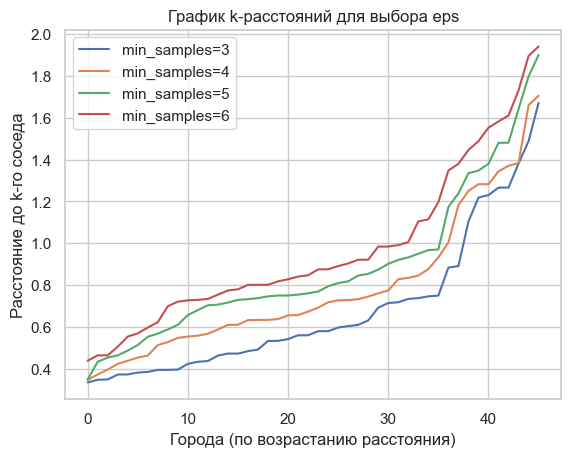

In [10]:
from sklearn.neighbors import NearestNeighbors

X = df.to_numpy()
for ms in [3, 4, 5, 6]:
    d, _ = NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)
    plt.plot(np.sort(d[:, -1]), label=f"min_samples={ms}")
plt.xlabel("Города (по возрастанию расстояния)")
plt.ylabel("Расстояние до k-го соседа")
plt.title("График k-расстояний для выбора eps")
plt.legend()
plt.show()

По графику k-расстояний видно, что в целом наш подбор совпадает с "советуемым" для m=4

###  Сравним результат с иерархической кластеризацией

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

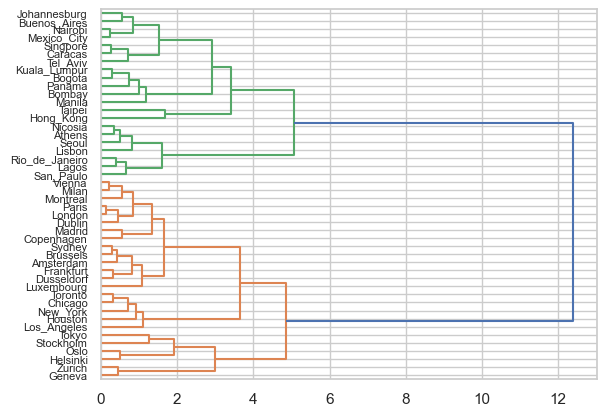

In [12]:
link = linkage(df, 'ward', 'euclidean')
dn = dendrogram(link, labels=df_raw['City'].values, orientation='right')


In [13]:
# строим таблицу сопряженности
tab = pd.crosstab(dbscan_2.labels_, fcluster(link, 4, criterion='maxclust'))

print(tab)


col_0  1   2  3   4
row_0              
-1     6   0  0   2
 0     0  19  0   0
 1     0   0  7  12


Кластеры "эталонные" из Иерархического анализа:
1. (сверхдорогие города) полностью попал в выбросы
2. (развитые города) полностью перешел в 0
3. (дешевые города) полностью перешел в 1
4. (дешевые города с большой работой) перешел в 2 выброса, остальное перешло в 1

In [14]:
df_raw["dbscan2"] = dbscan_2.labels_
df_raw["cluster"] = fcluster(link, 4, criterion='maxclust')


In [15]:
df_raw[['City', 'dbscan2', 'cluster']].sort_values('dbscan2')

,City,dbscan2,cluster
14,Hong_Kong,-1,4
12,Geneva,-1,1
13,Helsinki,-1,1
31,Oslo,-1,1
40,Taipei,-1,4
42,Tokyo,-1,1
45,Zurich,-1,1
38,Stockholm,-1,1
9,Dublin,0,2
10,Dusseldorf,0,2


In [16]:
# еще раз - распределение по кластерам
print(np.asarray((unique, counts)).T)
# берем средние признаки по каждому кластеру
df_raw[['Work', 'Price', 'Salary', 'dbscan2']].groupby("dbscan2").mean(numeric_only=True)

[[-1  8]
 [ 0 19]
 [ 1 19]]


,Work,Price,Salary
dbscan2,,,
-1,1900.375000,99.925000,61.262500
0,1792.000000,77.526316,55.157895
1,1959.210526,50.115789,14.789474


Интерпретация:

0. Экономически развитые города
1. Бедные города

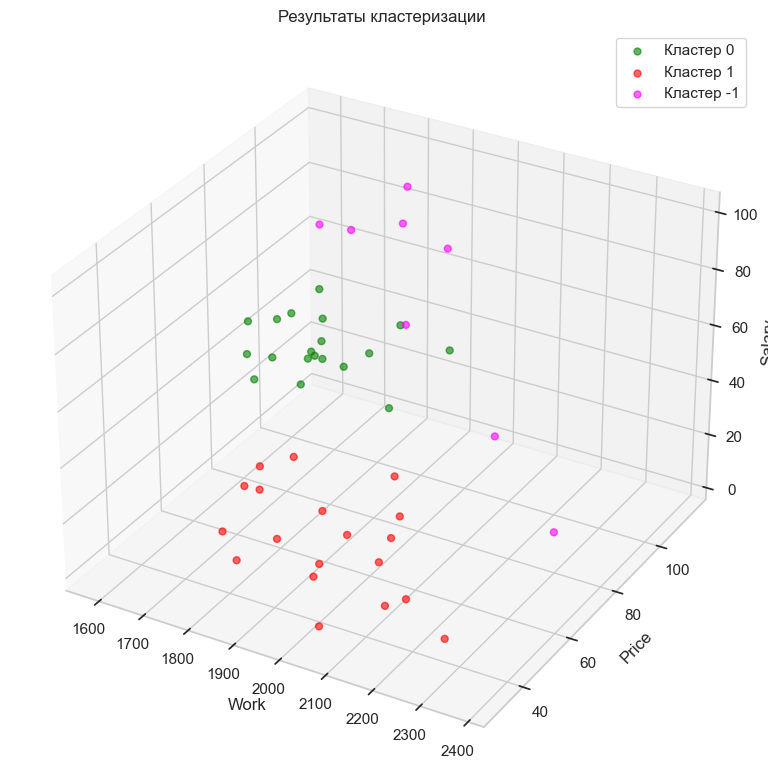

In [17]:
# цвет точки --- номер кластера
palette = {-1: "magenta", 0: "green", 1: "red"}

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for label in df_raw['dbscan2'].unique():
    sub = df_raw[df_raw['dbscan2'] == label]
    color = palette[label]
    ax.scatter(sub['Work'], sub['Price'], sub['Salary'],
               c=color, label=f'Кластер {label}', alpha=0.6, s=25)

ax.set_xlabel('Work')
ax.set_ylabel('Price')
ax.set_zlabel('Salary')
ax.set_title('Результаты кластеризации')
ax.legend()
plt.tight_layout()
plt.show()

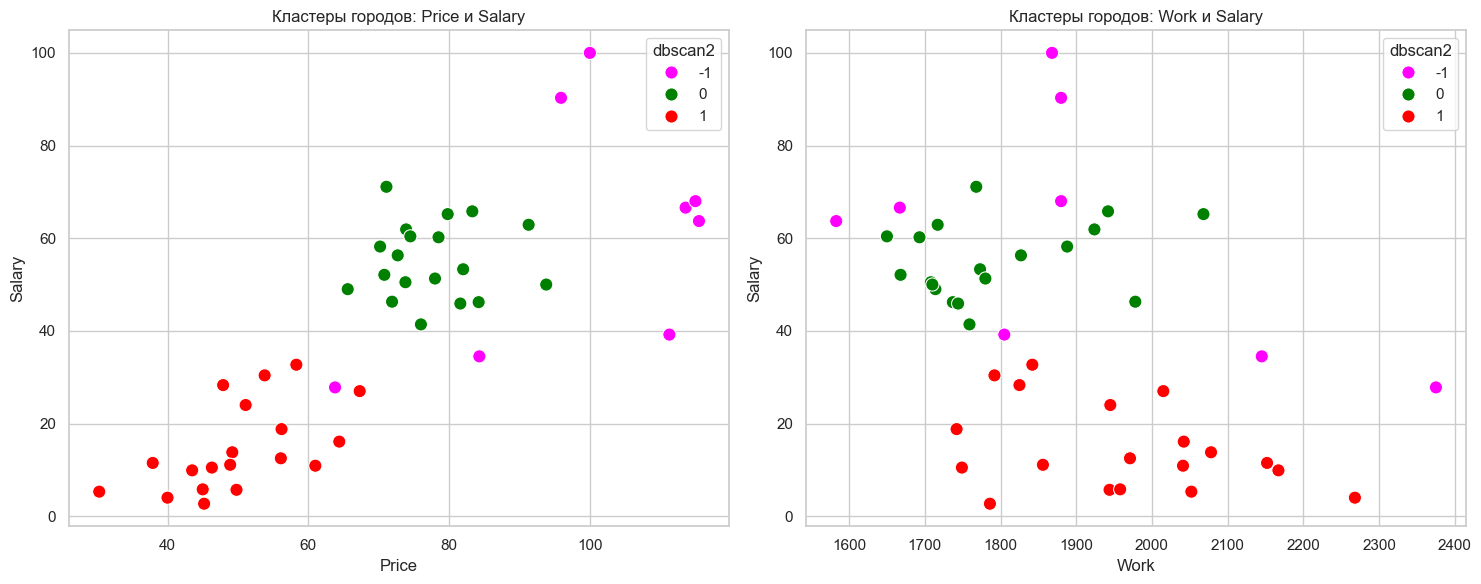

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (a, b) in zip(axes, [("Price", "Salary"), ("Work", "Salary")]):
  sns.scatterplot(
      data=df_raw, x=a, y=b, hue="dbscan2", palette=palette, s=90, ax=ax
  )
  ax.set_title(f"Кластеры городов: {a} и {b}")
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import plotly.express as px

cities_coords = {
    'Amsterdam': (52.3676, 4.9041),
    'Athens': (37.9838, 23.7275),
    'Bogota': (4.7110, -74.0721),
    'Bombay': (19.0760, 72.8777),
    'Brussels': (50.8503, 4.3517),
    'Buenos_Aires': (-34.6037, -58.3816),
    'Caracas': (10.4806, -66.9036),
    'Chicago': (41.8781, -87.6298),
    'Copenhagen': (55.6761, 12.5683),
    'Dublin': (53.3498, -6.2603),
    'Dusseldorf': (51.2277, 6.7735),
    'Frankfurt': (50.1109, 8.6821),
    'Geneva': (46.2044, 6.1432),
    'Helsinki': (60.1699, 24.9384),
    'Hong_Kong': (22.3193, 114.1694),
    'Houston': (29.7604, -95.3698),
    'Johannesburg': (-26.2041, 28.0473),
    'Kuala_Lumpur': (3.1390, 101.6869),
    'Lagos': (6.5244, 3.3792),
    'Lisbon': (38.7223, -9.1393),
    'London': (51.5072, -0.1276),
    'Los_Angeles': (34.0522, -118.2437),
    'Luxembourg': (49.6116, 6.1319),
    'Madrid': (40.4168, -3.7038),
    'Manila': (14.5995, 120.9842),
    'Mexico_City': (19.4326, -99.1332),
    'Milan': (45.4642, 9.1900),
    'Montreal': (45.5017, -73.5673),
    'Nairobi': (-1.2921, 36.8219),
    'New_York': (40.7128, -74.0060),
    'Nicosia': (35.1856, 33.3823),
    'Oslo': (59.9139, 10.7522),
    'Panama': (8.9824, -79.5199),
    'Paris': (48.8566, 2.3522),
    'Rio_de_Janeiro': (-22.9068, -43.1729),
    'San_Paulo': (-23.5505, -46.6333),
    'Seoul': (37.5665, 126.9780),
    'Singpore': (1.3521, 103.8198),
    'Stockholm': (59.3293, 18.0686),
    'Sydney': (-33.8688, 151.2093),
    'Taipei': (25.0330, 121.5654),
    'Tel_Aviv': (32.0853, 34.7818),
    'Tokyo': (35.6762, 139.6503),
    'Toronto': (43.6532, -79.3832),
    'Vienna': (48.2082, 16.3738),
    'Zurich': (47.3769, 8.5417),
}

df_raw['lat'] = df_raw['City'].map(lambda x: cities_coords.get(x, (None, None))[0])
df_raw['lon'] = df_raw['City'].map(lambda x: cities_coords.get(x, (None, None))[1])

df_raw['cluster_label'] = df_raw['dbscan2'].astype(str)

palette_str = {"-1": "magenta", "0": "green", "1": "red"}


fig = px.scatter_geo(
    df_raw,
    lat='lat',
    lon='lon',
    color='cluster_label',
    color_discrete_map=palette_str,
    hover_name='City',
    hover_data={'Work': True, 'Price': True, 'Salary': True, 'lat': False, 'lon': False, 'cluster_label': False},
    height=600,
    title='Карта'
)

fig.update_traces(marker=dict(size=10, line=dict(width=1, color='white')))
fig.update_layout(legend_title_text='Кластер (dbscan2)')

fig.show(renderer='iframe')

## Анализ выбросов

In [20]:
# еще раз берем средние признаки по каждому кластеру
df_raw[['Work', 'Price', 'Salary', 'dbscan2']].groupby("dbscan2").mean(numeric_only=True)

,Work,Price,Salary
dbscan2,,,
-1,1900.375000,99.925000,61.262500
0,1792.000000,77.526316,55.157895
1,1959.210526,50.115789,14.789474


In [21]:
# смотрим на выбросы
df_raw[df_raw['dbscan2'] == -1][['City', 'Work', 'Price', 'Salary']].sort_values(by='Work')

,City,Work,Price,Salary
31,Oslo,1583.0,115.5,63.7
13,Helsinki,1667.0,113.6,66.6
38,Stockholm,1805.0,111.3,39.2
45,Zurich,1868.0,100.0,100.0
42,Tokyo,1880.0,115.0,68.0
12,Geneva,1880.0,95.9,90.3
40,Taipei,2145.0,84.3,34.5
14,Hong_Kong,2375.0,63.8,27.8


Hong_Kong, Taipei --- слишком много работы

In [22]:
seen_cities = {'Taipei', 'Hong_Kong'}
subset = df_raw[
    (df_raw['dbscan2'] == -1) & (~df_raw['City'].isin(seen_cities))
][['City', 'Work', 'Price', 'Salary']].sort_values(by='Salary')
subset

,City,Work,Price,Salary
38,Stockholm,1805.0,111.3,39.2
31,Oslo,1583.0,115.5,63.7
13,Helsinki,1667.0,113.6,66.6
42,Tokyo,1880.0,115.0,68.0
12,Geneva,1880.0,95.9,90.3
45,Zurich,1868.0,100.0,100.0


Zurich, Geneva --- слишком высокие зп

In [23]:
seen_cities.update({'Zurich', 'Geneva'})
subset = df_raw[
    (df_raw['dbscan2'] == -1) & (~df_raw['City'].isin(seen_cities))
][['City', 'Work', 'Price', 'Salary']].sort_values(by='Price')
subset

,City,Work,Price,Salary
38,Stockholm,1805.0,111.3,39.2
13,Helsinki,1667.0,113.6,66.6
42,Tokyo,1880.0,115.0,68.0
31,Oslo,1583.0,115.5,63.7


Oslo, Tokyo, Helsinki --- слишком высокие цены

Stockholm --- тоже, но

Не образуют кластер, т.к. у него относительно них слишком низкая ЗП + слишком разные рабочие часы

## 4. Итоги

Кластеризовали с помощью DBSCAN на 2 кластера. Один кластер полностью совпал с Иерархическим кластерным анализом, второй включил в себя несколько кластеров. Также обнаружили 8 "выбросов", объяснили их природу.

Такая кластеризация имеет место быть, но ее недостатком является наличие такого большого количества "выбросов".